In [34]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [35]:
A = 0.22
r0 = 3.0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0
num_output_times = 101
dt0 = 0.010062893081761

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [36]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [37]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [38]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [39]:
initial_state = make_initial_state(A)

Ham, Mom = get_constraints_diagnostic(
    initial_state,
    jnp.array([0.0]),
    grid,
    background,
    matter,
)

# Exclude the ghost cells and the last two physical points,
# where the outer boundary can affect the finite-difference stencil.
interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(jnp.abs(Ham[0, interior]))
mom_error = jnp.max(
    jnp.linalg.norm(Mom[0, interior], axis=-1)
)

print("All initial-state values finite:",
      bool(jnp.all(jnp.isfinite(initial_state))))
print("All psi values positive:",
      bool(jnp.all(solve_psi(r_physical, dr, A, r0, sigma) > 0)))
print("Largest interior Hamiltonian constraint:", float(ham_error))
print("Largest interior momentum constraint:", float(mom_error))

All initial-state values finite: True
All psi values positive: True
Largest interior Hamiltonian constraint: 0.0013118366889146933
Largest interior momentum constraint: 0.0


In [40]:
def evolve(amplitude):
    y0 = make_initial_state(amplitude)

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter)

    save_times = jnp.linspace(0.0, T, num_output_times)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=T,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=dfx.SaveAt(ts=save_times),
        adjoint=dfx.ForwardMode(),
        max_steps=700,
    )

    return solution

def central_scalar_variation(amplitude):
    solution = evolve(amplitude)

    history = solution.ys.reshape(
        solution.ts.size, grid.NUM_VARS, grid.N
    )

    # The first physical radial point is our simple proxy for the centre.
    u_centre = history[:, matter.idx_u, NUM_GHOSTS]

    # Total change in the central scalar over the saved evolution.
    return jnp.sum(jnp.abs(jnp.diff(u_centre)))

In [41]:
amplitude = jnp.asarray(A, dtype=jnp.float64)

value, dvalue_dA = jax.jvp(
    central_scalar_variation,
    (amplitude,),
    (jnp.ones_like(amplitude),),
)

print("scalar variation:", value)
print("change in scalar variation per unit amplitude:", dvalue_dA)

scalar variation: 0.5184758390865383
change in scalar variation per unit amplitude: 3.1969241949170986


In [42]:
delta = 1e-4

finite_difference = (
    central_scalar_variation(A + delta)
    - central_scalar_variation(A - delta)
) / (2 * delta)

print("JVP:", dvalue_dA)
print("finite difference:", finite_difference)

JVP: 3.1969241949170986
finite difference: 3.1969201416909288


In [43]:
for A_test in [A - 0.01, A, A + 0.01]:
    amplitude = jnp.asarray(A_test, dtype=jnp.float64)

    value, sensitivity = jax.jvp(
        central_scalar_variation,
        (amplitude,),
        (jnp.ones_like(amplitude),),
    )

    print(
        f"A={float(amplitude):.4f}: "
        f"variation={float(value):.6f}, "
        f"d(variation)/dA={float(sensitivity):.6f}"
    )

A=0.2100: variation=0.489216, d(variation)/dA=3.079335
A=0.2200: variation=0.518476, d(variation)/dA=3.196924
A=0.2300: variation=0.548692, d(variation)/dA=3.277391


Minimum innermost physical lapse: 0.5636554071139321


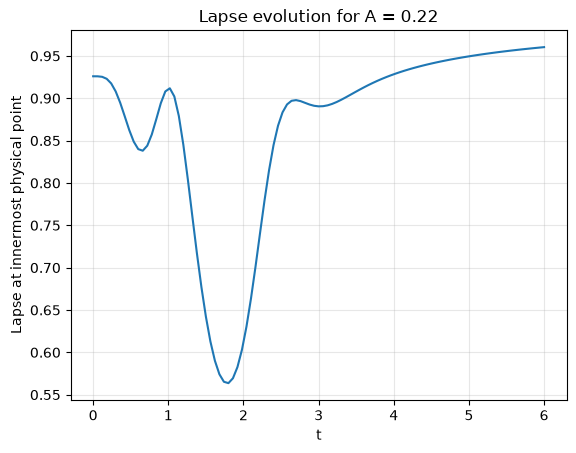

In [44]:
solution = evolve(A)

state_history = solution.ys.reshape(
    solution.ts.size,
    grid.NUM_VARS,
    grid.N,
)
lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]

print("Minimum innermost physical lapse:",
      float(jnp.min(lapse_history)))

plt.plot(solution.ts, lapse_history)
plt.xlabel("t")
plt.ylabel("Lapse at innermost physical point")
plt.title(f"Lapse evolution for A = {A:.2f}")
plt.grid(alpha=0.3)
plt.show()

In [45]:
lapse_initial = state_history[0, idx_lapse]
lapse_final = state_history[-1, idx_lapse]

print("Maximum lapse change anywhere on grid:",
      float(jnp.max(jnp.abs(lapse_final - lapse_initial))))
print("Lapse change at innermost physical point:",
      float(lapse_final[NUM_GHOSTS] - lapse_initial[NUM_GHOSTS]))
print("Maximum change in the full state:",
      float(jnp.max(jnp.abs(solution.ys[-1] - solution.ys[0]))))

Maximum lapse change anywhere on grid: 0.04169415685805922
Lapse change at innermost physical point: 0.03440275276208882
Maximum change in the full state: 0.0832181726810981


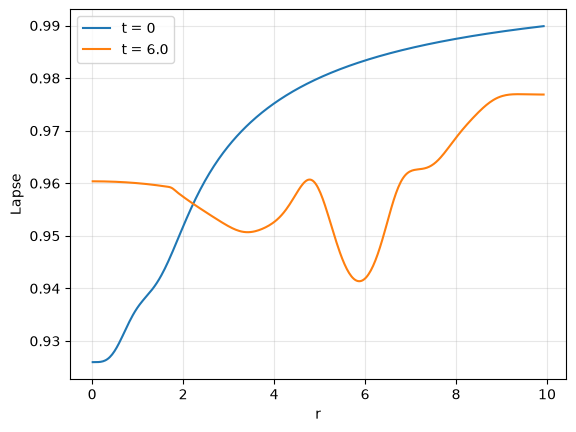

In [46]:
plt.plot(grid.r[physical], lapse_initial[physical], label="t = 0")
plt.plot(grid.r[physical], lapse_final[physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("Lapse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Maximum scalar-field change: 0.08088255944513496


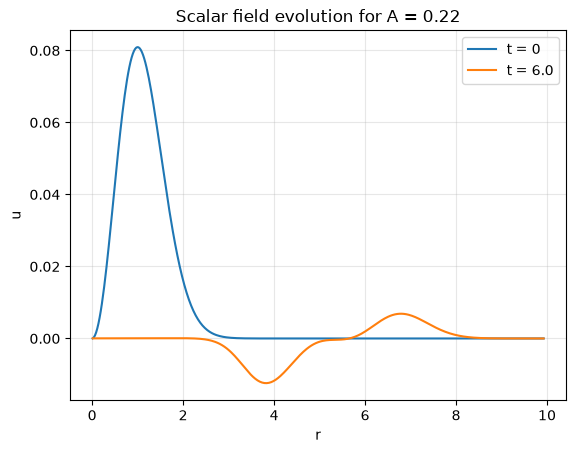

In [47]:
u_history = state_history[:, matter.idx_u, :]

print("Maximum scalar-field change:",
      float(jnp.max(jnp.abs(u_history[-1] - u_history[0]))))

plt.plot(grid.r[physical], u_history[0, physical], label="t = 0")
plt.plot(grid.r[physical], u_history[-1, physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("u")
plt.title(f"Scalar field evolution for A = {A:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Check that constraints are satisfied

In [48]:
Ham_history, Mom_history = get_constraints_diagnostic(
    solution.ys,
    solution.ts,
    grid,
    background,
    matter,
)

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)
mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

print("Largest interior Hamiltonian constraint at t=0:",
      float(ham_error[0]))
print("Largest interior Hamiltonian constraint at t=6:",
      float(ham_error[-1]))
print("Largest interior momentum constraint at t=6:",
      float(mom_error[-1]))

Largest interior Hamiltonian constraint at t=0: 0.0013118366889146933
Largest interior Hamiltonian constraint at t=6: 0.015216400685871162
Largest interior momentum constraint at t=6: 0.005587750336058574


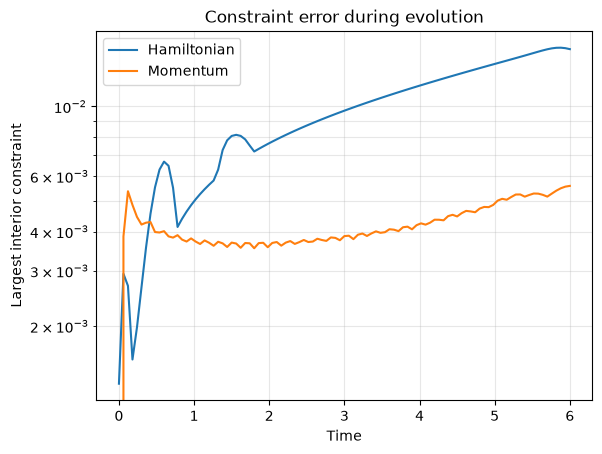

t=0.00: H=0.00131184, M=0
t=1.50: H=0.00805632, M=0.00368829
t=3.00: H=0.00969501, M=0.00386835
t=4.50: H=0.0126321, M=0.00446759
t=6.00: H=0.0152164, M=0.00558775


In [49]:
import matplotlib.pyplot as plt

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)

mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

plt.semilogy(solution.ts, ham_error, label="Hamiltonian")
plt.semilogy(solution.ts, mom_error, label="Momentum")
plt.xlabel("Time")
plt.ylabel("Largest interior constraint")
plt.title("Constraint error during evolution")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

for i in [0, 25, 50, 75, 100]:
    print(
        f"t={float(solution.ts[i]):.2f}: "
        f"H={float(ham_error[i]):.6g}, "
        f"M={float(mom_error[i]):.6g}"
    )

In [50]:
H0 = jnp.abs(Ham_history[0, interior])
local_i = int(jnp.argmax(H0))
i = local_i + NUM_GHOSTS

print("Initial H maximum:", float(H0[local_i]))
print("At r =", float(grid.r[i]))

Initial H maximum: 0.0013118366889146933
At r = 0.012578616352200613


In [51]:
print("dr =", float(dr))
print("first physical radius =", float(r_physical[0]))
print("radius / dr =", float(r_physical[0] / dr))

dr = 0.025157232704402514
first physical radius = 0.012578616352200613
radius / dr = 0.4999999999999744


In [52]:
state = make_initial_state(A).reshape(grid.NUM_VARS, grid.N)
psi_physical = solve_psi(
        r_physical, dr, 0.2, r0, sigma
    )
print(state[idx_lapse, physical][:5])
print((psi_physical**-2)[:5])

[0.92596608 0.92596612 0.92596673 0.92596898 0.92597439]
[0.93853186 0.93853189 0.9385324  0.93853428 0.93853882]


In [53]:
print(matter.scalar_mu)

0.0


In [54]:
h_final = Ham[-1, physical]
m_final = Mom[-1, physical, :]

print("last saved time:", solution.ts[-1])
print("final state is finite:", jnp.all(jnp.isfinite(solution.ys[-1])))
print("finite H values:", jnp.count_nonzero(jnp.isfinite(h_final)), "/", h_final.size)
print("finite M values:", jnp.count_nonzero(jnp.isfinite(m_final)), "/", m_final.size)

last saved time: 6.0
final state is finite: True
finite H values: 395 / 395
finite M values: 1185 / 1185


In [55]:
final_grid = solution.ys[-1].reshape(grid.NUM_VARS, grid.N)

for i, name in enumerate(state_vector.VARIABLE_NAMES):
    bad_points = jnp.where(~jnp.isfinite(final_grid[i]))[0]
    if bad_points.size > 0:
        print(name, "bad grid points:", bad_points[:10])

In [56]:
print("max |H|:", jnp.max(jnp.abs(h_final)))
print("max |M|:", jnp.max(jnp.abs(m_final)))

max |H|: 0.0013118366889146933
max |M|: 0.0


In [57]:
history = solution.ys.reshape(
    solution.ts.size, grid.NUM_VARS, grid.N
)

bad_times = jnp.where(
    ~jnp.all(jnp.isfinite(history), axis=(1, 2))
)[0]
if bad_times.size == 0:
    print("All saved states are finite.")
else:
    print("First saved time with non-finite values:", solution.ts[bad_times[0]])

All saved states are finite.


In [58]:
idx_K = list(state_vector.VARIABLE_NAMES).index("K")
idx_lapse = list(state_vector.VARIABLE_NAMES).index("lapse")
for i, t_i in enumerate(solution.ts):
    if t_i > 0.36:
        break

    state_i = history[i]
    print(
        f"t={float(t_i):.2f}",
        "minimum lapse =", float(jnp.min(state_i[idx_lapse, physical])),
        "maximum |K| =", float(jnp.max(jnp.abs(state_i[idx_K, physical]))),
    )

t=0.00 minimum lapse = 0.9259660827428208 maximum |K| = 0.0
t=0.06 minimum lapse = 0.9259243381116998 maximum |K| = 0.0046407637114579126
t=0.12 minimum lapse = 0.9253326942484971 maximum |K| = 0.011053731297190707
t=0.18 minimum lapse = 0.9229949744741346 maximum |K| = 0.033322725197160126
t=0.24 minimum lapse = 0.9175270605987128 maximum |K| = 0.06723790643440743
t=0.30 minimum lapse = 0.9080378840478307 maximum |K| = 0.10604215301520667
t=0.36 minimum lapse = 0.8946667576819375 maximum |K| = 0.13935121019837174


In [59]:
print("minimum grid spacing:", float(grid.min_dr))
print("recommended fixed dt:", 0.4 * float(grid.min_dr))

minimum grid spacing: 0.025157232704401622
recommended fixed dt: 0.01006289308176065


In [60]:
h_values = jnp.abs(Ham[-1, physical])
h_local = int(jnp.argmax(h_values))
h_grid = h_local + NUM_GHOSTS
print("H maximum at r =", grid.r[h_grid])
print("H value =", Ham[-1, h_grid])

m_values = jnp.max(jnp.abs(Mom[-1, physical, :]), axis=-1)
m_local = int(jnp.argmax(m_values))
m_grid = m_local + NUM_GHOSTS
print("M maximum at r =", grid.r[m_grid])
print("M components =", Mom[-1, m_grid, :])

H maximum at r = 0.012578616352200613
H value = -0.0013118366889146933
M maximum at r = 0.012578616352200613
M components = [0. 0. 0.]


In [61]:
Ham, Mom = get_constraints_diagnostic(
    solution.ys, solution.ts, grid, background, matter
)

h = Ham[-1, physical]
m = Mom[-1, physical, :]

print("last time:", solution.ts[-1])
print("H shape:", Ham.shape, "M shape:", Mom.shape)
print("max |H|:", jnp.max(jnp.abs(h)))
print("max |M|:", jnp.max(jnp.abs(m)))

h_local = int(jnp.argmax(jnp.abs(h)))
m_local = int(jnp.argmax(jnp.max(jnp.abs(m), axis=-1)))
print("H at its max:", h[h_local], "radius:", grid.r[h_local + NUM_GHOSTS])
print("M at its max:", m[m_local], "radius:", grid.r[m_local + NUM_GHOSTS])

last time: 6.0
H shape: (101, 401) M shape: (101, 401, 3)
max |H|: 0.01848168795464149
max |M|: 0.005587750336058574
H at its max: -0.01848168795464149 radius: 9.89937106918239
M at its max: [-0.00558775  0.          0.        ] radius: 4.1886792452830175


In [62]:
r_physical = grid.r[physical]
away_from_outer_edge = r_physical < 9.0

h_bulk = jnp.abs(h[away_from_outer_edge])
m_bulk = jnp.max(jnp.abs(m[away_from_outer_edge]), axis=-1)

h_i = int(jnp.argmax(h_bulk))
m_i = int(jnp.argmax(m_bulk))

print("max |H| for r < 9:", h_bulk[h_i],
      "at r =", r_physical[away_from_outer_edge][h_i])
print("max |M| for r < 9:", m_bulk[m_i],
      "at r =", r_physical[away_from_outer_edge][m_i])

max |H| for r < 9: 0.0025522872404521516 at r = 0.012578616352200613
max |M| for r < 9: 0.005587750336058574 at r = 4.1886792452830175
